# Laboratorio 1 · ML clásico vs. QML con Qiskit
**Workshop de computación cuántica · SCAYLE · Bloque 3: Quantum Machine Learning**

En este cuaderno compararás tres clasificadores sobre **los mismos datos** y con **la misma API** (`fit` / `score`):

| Modelo | Tipo | Qué hace el ordenador cuántico |
|---|---|---|
| `SVC` (kernel RBF) | Clásico | Nada: es la referencia |
| `QSVC` | Kernel cuántico + SVM clásica | Calcula la similitud entre puntos, $k(x,x') = |\langle\varphi(x')|\varphi(x)\rangle|^2$ |
| `VQC` | Clasificador variacional | Es el modelo completo: un circuito con parámetros entrenables |

**Duración:** unos 12 minutos. Todo se ejecuta en un simulador, en la CPU de tu portátil.

**Antes de empezar:** crea el entorno con `pip install -r requirements.txt` y ejecuta las celdas **en orden** (*Run All* o `Mayús + Intro` celda a celda).

## 0. Importaciones y comprobación del entorno
La primera celda importa todo lo necesario y muestra las versiones. Si alguna no coincide con el `requirements.txt`, los resultados pueden variar.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import sklearn, qiskit, qiskit_machine_learning

from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import ConfusionMatrixDisplay

from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit.primitives import StatevectorSampler
from qiskit_machine_learning.state_fidelities import ComputeUncompute
from qiskit_machine_learning.kernels import FidelityQuantumKernel, FidelityStatevectorKernel
from qiskit_machine_learning.algorithms import QSVC, VQC
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals

SEMILLA = 42
algorithm_globals.random_seed = SEMILLA   # fija la aleatoriedad de Qiskit ML (p. ej., el punto inicial del VQC)

print(f"qiskit {qiskit.__version__} · qiskit-machine-learning {qiskit_machine_learning.__version__} · "
      f"scikit-learn {sklearn.__version__} · numpy {np.__version__}")

qiskit 2.6.1 · qiskit-machine-learning 0.9.1 · scikit-learn 1.9.1 · numpy 2.5.3


## 1. Datos: Iris reducido a 2 características
Iris tiene 150 flores, 4 medidas por flor y 3 especies (setosa, versicolor y virginica). Lo preparamos en cuatro pasos:

1. **Estandarizar** (media 0, desviación típica 1), para que todas las medidas pesen lo mismo.
2. **PCA a 2 componentes**: cada característica irá a un qubit, así que 2 características = **2 qubits**. Simular $n$ qubits cuesta memoria proporcional a $2^n$; con 2 qubits, el laboratorio va rápido en cualquier portátil.
3. **Escalar a $[0, \pi]$**: las características se usarán como **ángulos** de rotación, que son periódicos. Sin este paso, valores muy distintos podrían acabar en el mismo estado cuántico.
4. **Partición estratificada 80/20** con semilla fija: 120 flores para entrenar y 30 para test, con las tres especies en la misma proporción.

In [2]:
X, y = load_iris(return_X_y=True)
X = StandardScaler().fit_transform(X)
X = PCA(n_components=2, random_state=SEMILLA).fit_transform(X)
X = MinMaxScaler(feature_range=(0, np.pi)).fit_transform(X)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, train_size=0.8, stratify=y, random_state=SEMILLA)

print("Entrenamiento:", X_tr.shape, "· Test:", X_te.shape)
print("Muestras por clase (entrenamiento):", np.bincount(y_tr), "· (test):", np.bincount(y_te))
print(f"Rango de las características: [{X.min():.2f}, {X.max():.2f}]  (debe ser [0, π] = [0, 3.14])")

Entrenamiento: (120, 2) · Test: (30, 2)
Muestras por clase (entrenamiento): [40 40 40] · (test): [10 10 10]
Rango de las características: [0.00, 3.14]  (debe ser [0, π] = [0, 3.14])


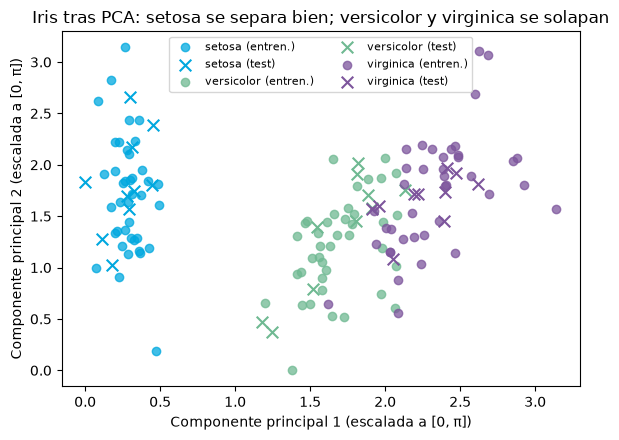

In [3]:
nombres = ["setosa", "versicolor", "virginica"]
fig, ax = plt.subplots(figsize=(6, 4.5))
for c, col in zip(range(3), ["#00A8DF", "#6FB992", "#7D559C"]):
    ax.scatter(*X_tr[y_tr == c].T, c=col, label=f"{nombres[c]} (entren.)", alpha=0.75)
    ax.scatter(*X_te[y_te == c].T, c=col, marker="x", s=70, label=f"{nombres[c]} (test)")
ax.set_xlabel("Componente principal 1 (escalada a [0, π])")
ax.set_ylabel("Componente principal 2 (escalada a [0, π])")
ax.set_title("Iris tras PCA: setosa se separa bien; versicolor y virginica se solapan")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

> **Observa:** setosa queda aislada, pero versicolor y virginica se solapan. Ningún modelo, clásico o cuántico, llegará al 100 % con solo estas 2 características: al reducir a 2 dimensiones se pierde información.

## 2. Referencia clásica: SVC con kernel RBF
Antes de usar nada cuántico necesitamos una **referencia**: un modelo clásico estándar, con su configuración por defecto. Cualquier afirmación del tipo «el modelo cuántico funciona bien» solo tiene sentido comparada con esta cifra.

In [4]:
t = time.time()
svc = SVC(kernel="rbf").fit(X_tr, y_tr)
print(f"SVC (RBF)  entren.={svc.score(X_tr, y_tr):.2f} test={svc.score(X_te, y_te):.2f}  tiempo={time.time()-t:.2f}s")

SVC (RBF)  entren.=0.92 test=0.90  tiempo=0.00s


## 3. El feature map ZZ: cómo entran los datos en los qubits
El *feature map* (codificación) convierte el vector clásico $x = (x_0, x_1)$ en un estado cuántico $|\varphi(x)\rangle$. Usamos el mapa ZZ de Havlíček et al. (*Nature*, 2019):

* una **Hadamard** en cada qubit;
* una **rotación de fase** $P(2x_i)$ en cada qubit;
* un bloque **CNOT – $P(2(\pi-x_0)(\pi-x_1))$ – CNOT**, que crea **entrelazamiento** dependiente de los datos.

El bloque se repite `reps` veces (2 en este laboratorio). Los nombres `x[0]` y `x[1]` del dibujo son los **parámetros** que se sustituyen por los datos de cada flor.

Parámetros del circuito: [ParameterVectorElement(x[0]), ParameterVectorElement(x[1])]
Profundidad (puertas básicas): 10


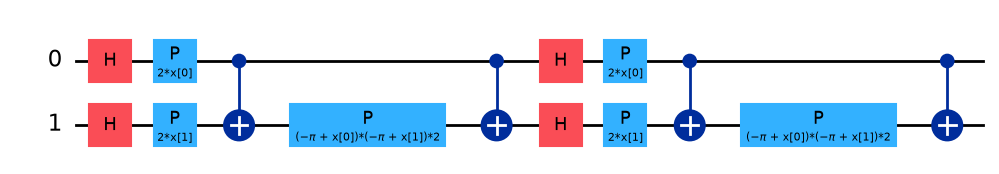

In [5]:
fmap = zz_feature_map(feature_dimension=2, reps=2)
print("Parámetros del circuito:", list(fmap.parameters))
print("Profundidad (puertas básicas):", fmap.decompose().depth())
fmap.draw("mpl", fold=-1)

## 4. Kernel cuántico + SVM clásica (QSVC)
**Idea:** el ordenador cuántico solo calcula **similitudes**. Para cada par de flores $(x, x')$:

$$k(x, x') = |\langle \varphi(x') | \varphi(x) \rangle|^2 \in [0, 1]$$

* $k = 1$: los dos estados son idénticos (siempre ocurre en la diagonal, $x = x'$).
* $k \approx 0$: los estados son casi ortogonales, «muy distintos».

Con esa matriz, una SVM **clásica** busca la frontera entre clases. Es un problema convexo y sin mínimos locales.

Usamos `FidelityStatevectorKernel`, que calcula los solapamientos **exactos** con el vector de estado: rápido e ideal para aprender. En un ordenador real solo se puede **estimar** midiendo muchas veces (*shots*); la celda opcional de más abajo lo prueba.

Matriz (120, 120): diagonal = 1.000; fuera de la diagonal: media 0.320, rango [0.000, 1.000]


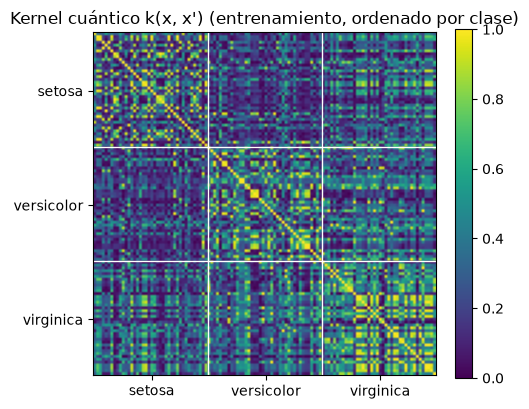

In [6]:
kernel = FidelityStatevectorKernel(feature_map=fmap)

# Matriz de kernel de entrenamiento, ordenada por clase para ver su estructura
orden = np.argsort(y_tr, kind="stable")
K_tr = kernel.evaluate(X_tr[orden])
fuera_diag = K_tr[~np.eye(len(K_tr), dtype=bool)]
print(f"Matriz {K_tr.shape}: diagonal = {np.diag(K_tr).min():.3f}; "
      f"fuera de la diagonal: media {fuera_diag.mean():.3f}, rango [{fuera_diag.min():.3f}, {fuera_diag.max():.3f}]")

fig, ax = plt.subplots(figsize=(5, 4.3))
im = ax.imshow(K_tr, cmap="viridis", vmin=0, vmax=1)
for b in (40, 80):
    ax.axhline(b - 0.5, color="white", lw=1); ax.axvline(b - 0.5, color="white", lw=1)
ax.set_xticks([20, 60, 100]); ax.set_xticklabels(nombres); ax.set_yticks([20, 60, 100]); ax.set_yticklabels(nombres)
ax.set_title("Kernel cuántico k(x, x') (entrenamiento, ordenado por clase)")
plt.colorbar(im, ax=ax, fraction=0.046); plt.tight_layout(); plt.show()

**Cómo leer la matriz:** cada bloque de la diagonal compara flores de la **misma** especie y los bloques de fuera comparan especies distintas. Un buen kernel debería dar valores más altos dentro de los bloques de la diagonal. La celda siguiente calcula la media de cada bloque.

¿Por qué aparece un 1,000 **fuera** de la diagonal? Iris contiene una flor repetida (dos filas con medidas idénticas) y ambas han caído en el conjunto de entrenamiento: dos puntos iguales tienen $k = 1$.

In [7]:
y_ord = y_tr[orden]
print("Media del kernel por bloque (filas y columnas: especie)")
print(" " * 12 + "".join(f"{n:>12s}" for n in nombres))
for a in range(3):
    fila = []
    for b in range(3):
        bloque = K_tr[np.ix_(y_ord == a, y_ord == b)]
        if a == b:
            bloque = bloque[~np.eye(len(bloque), dtype=bool)]   # sin la diagonal (siempre 1)
        fila.append(bloque.mean())
    print(f"{nombres[a]:>12s}" + "".join(f"{v:12.3f}" for v in fila))

Media del kernel por bloque (filas y columnas: especie)
                  setosa  versicolor   virginica
      setosa       0.339       0.219       0.308
  versicolor       0.219       0.383       0.326
   virginica       0.308       0.326       0.462


> **Observa:** dentro de cada especie el kernel es mayor (0,34 / 0,38 / 0,46) que entre setosa y versicolor (0,22), como debe ser. Pero **setosa–virginica vale 0,31**, casi lo mismo que setosa–setosa (0,34): en la gráfica están en extremos opuestos y, sin embargo, el kernel las ve bastante parecidas. Es un efecto de codificar los datos como **ángulos**: las funciones periódicas pueden «acercar» puntos lejanos. Un kernel cuántico no tiene por qué respetar la geometría de los datos.

In [8]:
t = time.time()
qsvc = QSVC(quantum_kernel=kernel).fit(X_tr, y_tr)
print(f"QSVC       entren.={qsvc.score(X_tr, y_tr):.2f} test={qsvc.score(X_te, y_te):.2f}  tiempo={time.time()-t:.2f}s")

QSVC       entren.=0.79 test=0.80  tiempo=0.38s


### 4.1 (Opcional) El mismo kernel estimado con *shots*
En hardware real cada valor $k(x,x')$ se **estima**: se ejecuta el circuito $U(x)\,U^\dagger(x')$ muchas veces y se cuenta cuántas sale $|00\rangle$. Cambia `PROBAR_SHOTS` a `True` para comprobarlo. Tarda **en torno a un minuto**, porque solo la matriz de entrenamiento son $120 \cdot 119 / 2 = 7140$ circuitos de 1.024 shots.

In [9]:
PROBAR_SHOTS = False   # cámbialo a True para probarlo (≈ 1 min)

if PROBAR_SHOTS:
    kernel_shots = FidelityQuantumKernel(
        fidelity=ComputeUncompute(sampler=StatevectorSampler(seed=SEMILLA)),   # 1.024 shots por defecto
        feature_map=fmap)
    t = time.time()
    qsvc_shots = QSVC(quantum_kernel=kernel_shots).fit(X_tr, y_tr)
    print(f"QSVC (shots) entren.={qsvc_shots.score(X_tr, y_tr):.2f} test={qsvc_shots.score(X_te, y_te):.2f}  "
          f"tiempo={time.time()-t:.1f}s")
else:
    print("Celda omitida (PROBAR_SHOTS = False).")

Celda omitida (PROBAR_SHOTS = False).


## 5. Clasificador cuántico variacional (VQC)
Ahora el circuito **es el modelo**: tras el feature map se añade un **ansatz** con parámetros $\theta$ (rotaciones $R_Y$ y CNOT), igual que las capas de una red neuronal. Funciona así:

1. Se ejecuta *feature map* + *ansatz* y se miden los 2 qubits → resultados `00`, `01`, `10`, `11` (enteros 0–3).
2. Cada resultado se asigna a una clase con **x mod 3**: `00`→0, `01`→1, `10`→2, `11`→0.
3. La pérdida es la **entropía cruzada**; el optimizador clásico **COBYLA** ajusta $\theta$ (sin gradientes).

> ⚠️ **Detalle importante:** hay que pasar `output_shape=3`. Sin él, qiskit-machine-learning 0.9 usa **2 clases** (x mod 2) aunque los datos tengan 3, y el modelo **nunca** puede predecir virginica, sin dar ningún aviso.

Parámetros entrenables del ansatz: 8


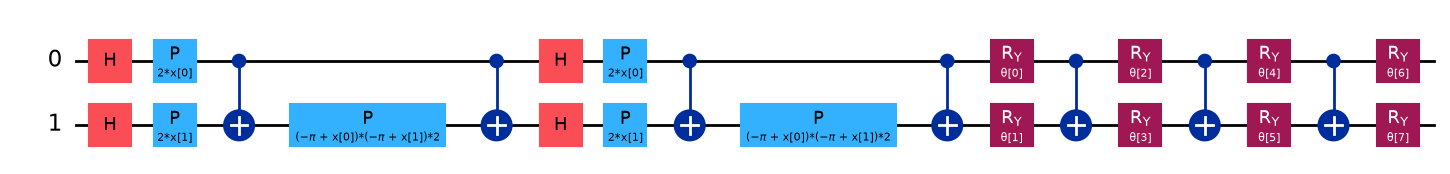

In [10]:
ansatz = real_amplitudes(num_qubits=2, reps=3)
print("Parámetros entrenables del ansatz:", ansatz.num_parameters)
fmap.compose(ansatz).draw("mpl", fold=-1)

El entrenamiento tarda **unos 30 segundos**. Guardamos la pérdida de cada evaluación (con un *callback*) para ver cómo aprende.

In [11]:
algorithm_globals.random_seed = SEMILLA   # mismo punto inicial aunque vuelvas a ejecutar esta celda
historial = []
vqc = VQC(sampler=StatevectorSampler(seed=SEMILLA), feature_map=fmap, ansatz=ansatz,
          optimizer=COBYLA(maxiter=100), output_shape=3,
          callback=lambda pesos, perdida: historial.append(perdida))
t = time.time()
vqc.fit(X_tr, y_tr)
print(f"VQC        entren.={vqc.score(X_tr, y_tr):.2f} test={vqc.score(X_te, y_te):.2f}  tiempo={time.time()-t:.2f}s")
print(f"COBYLA usó {len(historial)} evaluaciones de la pérdida (el máximo permitido era 100).")

VQC        entren.=0.65 test=0.67  tiempo=27.45s
COBYLA usó 86 evaluaciones de la pérdida (el máximo permitido era 100).


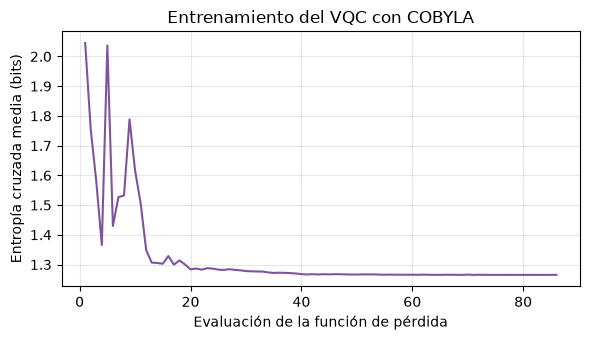

In [12]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(range(1, len(historial) + 1), historial, color="#7D559C")
ax.set_xlabel("Evaluación de la función de pérdida"); ax.set_ylabel("Entropía cruzada media (bits)")
ax.set_title("Entrenamiento del VQC con COBYLA"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

> **Observa:** la pérdida baja deprisa al principio y luego se estanca. COBYLA se detiene **antes** del límite de 100 evaluaciones porque considera que ha convergido. Lo explorarás en el reto 5.

## 6. Comparación final
Mismos datos y misma partición: solo cambia el modelo.

SVC (RBF) clásico            entren.=0.92  test=0.90
QSVC kernel cuántico         entren.=0.79  test=0.80
VQC variacional              entren.=0.65  test=0.67


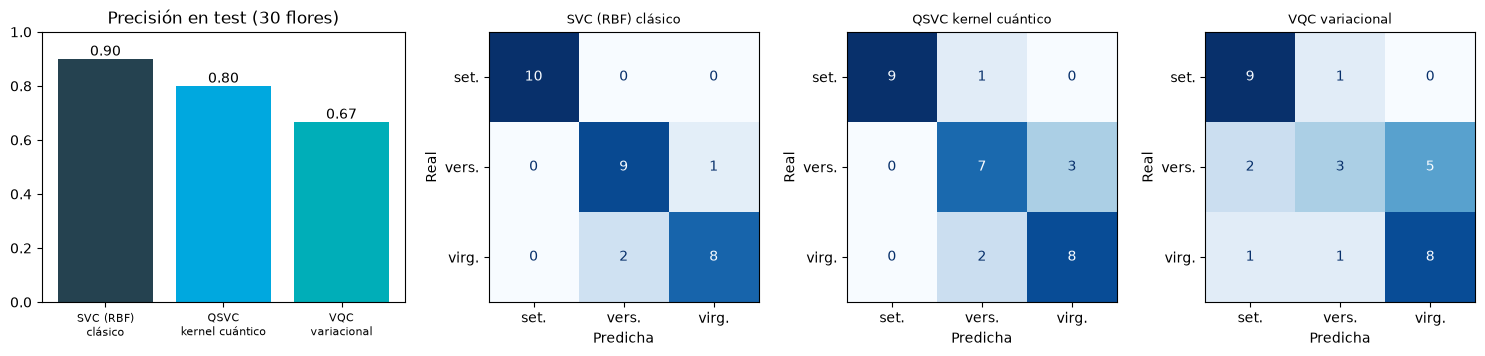

In [13]:
modelos = {"SVC (RBF)\nclásico": svc, "QSVC\nkernel cuántico": qsvc, "VQC\nvariacional": vqc}
resultados = {n: (m.score(X_tr, y_tr), m.score(X_te, y_te)) for n, m in modelos.items()}
for n, (a_tr, a_te) in resultados.items():
    print(f"{n.replace(chr(10), ' '):28s} entren.={a_tr:.2f}  test={a_te:.2f}")

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1.3, 1, 1, 1]})
nombres_m = list(resultados)
barras = axes[0].bar(range(3), [resultados[n][1] for n in nombres_m], color=["#254250", "#00A8DF", "#00AEB8"])
axes[0].bar_label(barras, fmt="%.2f"); axes[0].set_xticks(range(3)); axes[0].set_xticklabels(nombres_m, fontsize=8)
axes[0].set_ylim(0, 1); axes[0].set_title("Precisión en test (30 flores)")
for ax, (n, m) in zip(axes[1:], modelos.items()):
    # from_predictions en lugar de from_estimator: con scikit-learn 1.9, QSVC y VQC no pasan
    # la comprobación interna de «es un clasificador», pero sus predicciones son normales
    ConfusionMatrixDisplay.from_predictions(y_te, m.predict(X_te), display_labels=["set.", "vers.", "virg."],
                                            ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(n.replace("\n", " "), fontsize=9); ax.set_xlabel("Predicha"); ax.set_ylabel("Real")
plt.tight_layout(); plt.show()

## 7. Conclusiones
* La **API es la misma** en los tres modelos: `QSVC` y `VQC` se integran en un pipeline de scikit-learn sin cambiar nada más.
* En este problema **gana el modelo clásico** (0,90), seguido de la QSVC (0,80) y del VQC (0,67). Es lo esperable en datasets clásicos pequeños y coincide con estudios amplios de benchmarking (Bowles, Ahmed y Schuld, 2024).
* **Cuidado con sobreinterpretar:** el test tiene 30 flores, así que **cada flor son 3,3 puntos** de precisión. No hemos ajustado hiperparámetros y usamos un simulador sin ruido.
* La lección de ingeniería: los modelos cuánticos son **una opción más** que hay que **validar** frente a una buena referencia clásica, no una mejora automática.

## 8. Retos (para los minutos finales o para casa)
1. **Codificación:** cambia `reps` del feature map a 1 y a 3 (celda de la Sección 3) y vuelve a ejecutar desde ahí. ¿Cómo cambian la precisión y la matriz de kernel?
2. **Shots:** pon `PROBAR_SHOTS = True`. ¿Cuánto más lento es? ¿Cambia la precisión?
3. **Optimizador:** cambia `COBYLA(maxiter=100)` por `COBYLA(maxiter=300)`. ¿Mejora el VQC? Fíjate en cuántas evaluaciones usa realmente.

*Apunta cada cambio y su resultado, como en cualquier registro de experimentos de ML.*